# One grid in depth

Every LV grid of pylovo is a pandapower net with geographic coordinates and the results of its power flow. This
notebook opens one rural grid, shows how its feeders, loading and voltage relate, draws it as a tree and saves it
for other tools.

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas).

In [1]:
plz = 85307          # 80805 München (urban), 85256 Vierkirchen (semi-urban), 85307 Paunzhausen (rural)
version_id = None    # None: the version of your configuration, or of the example data
grid = None          # (kcid, bcid); None: the typical grid of the area

In [2]:
import matplotlib.pyplot as plt

from pylovo.examples import TutorialData
from pylovo.plotting import lv_grid, style

style.apply_style(dpi=150)
data = TutorialData(plz, version_id)
data

TutorialData(plz=85307, version 1, from the example data: no database configured)

## 1 The pandapower model

One transformer, the buses of the cable joints and houses, the cables between them and one load per house.

In [3]:
kcid, bcid = grid or data.typical_grid
net = data.net(kcid, bcid)
net

This pandapower network includes the following parameter tables:
   - bus (71 elements)
   - load (35 elements)
   - ext_grid (1 element)
   - line (69 elements)
   - trafo (1 element)
 and the following results tables:
   - res_bus (71 elements)
   - res_line (69 elements)
   - res_trafo (1 element)
   - res_ext_grid (1 element)
   - res_load (35 elements)

In [4]:
net.trafo[["name", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "tap_pos"]]

,name,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,tap_pos
0,single 250 kva transformer,0.25,20.0,0.4,6.0,0.0


In [5]:
net.line[["std_type", "length_km", "parallel", "max_i_ka", "feeder_sizing_basis"]].head()

,std_type,length_km,parallel,max_i_ka,feeder_sizing_basis
0,NAYY_4_150,0.017960,1,0.27,ampacity
1,NAYY_4_150,0.342596,1,0.27,ampacity
2,NAYY_4_150,0.073810,1,0.27,ampacity
3,NAYY_4_150,0.019831,1,0.27,ampacity
4,NAYY_4_150,0.005725,1,0.27,ampacity


In [6]:
net.load[["category", "p_mw", "max_p_mw", "load_units"]].head()

,category,p_mw,max_p_mw,load_units
0,Residential,0.003995,0.033650,2.0
1,Residential,0.001998,0.016825,1.0
2,Residential,0.001998,0.016825,1.0
3,Residential,0.001998,0.016825,1.0
4,Residential,0.003995,0.033650,2.0


`p_mw` is the load of the house in the power flow at the peak of the whole grid, `max_p_mw` its own peak. With
many houses their peaks do not coincide, which is why the station can be smaller than the sum of `max_p_mw`.

## 2 Feeders and their voltage

Each cable that leaves the busbar starts a feeder. The map and the profile use the same feeder colours, so you can
follow each feeder from the map to its voltage curve.

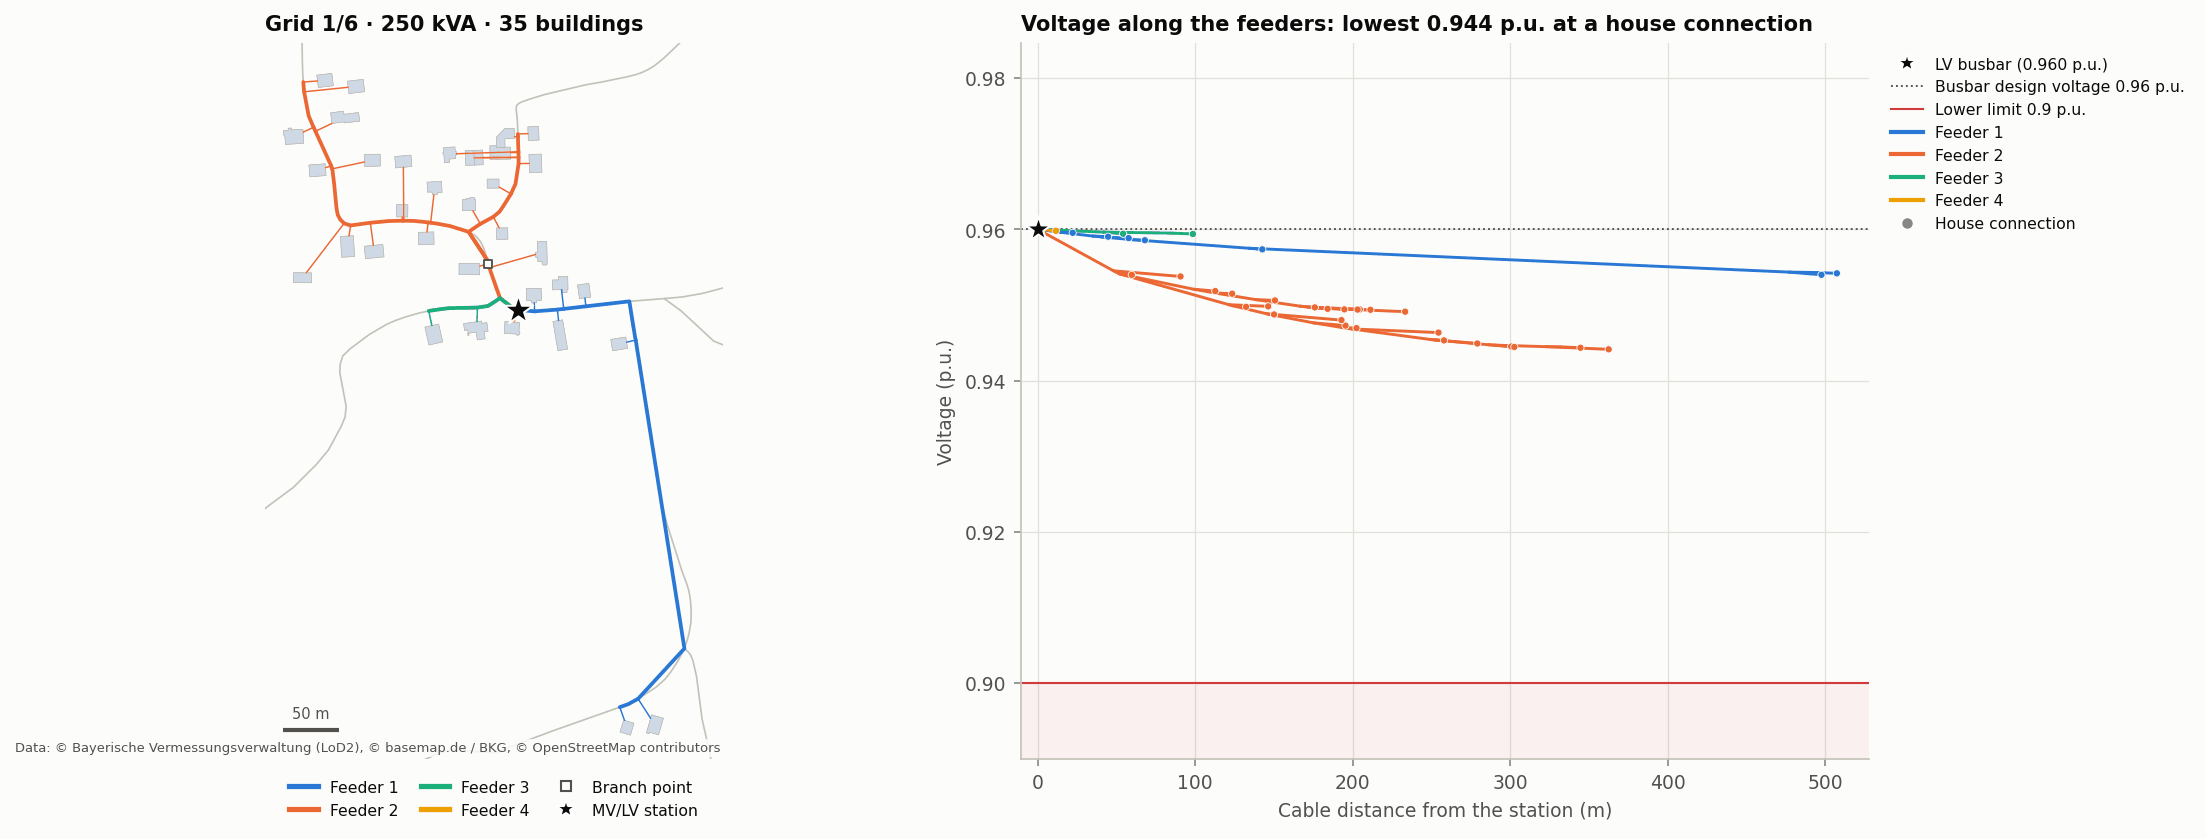

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.15]})
lv_grid.plot_lv_grid(data.layers, kcid, bcid, color_by="feeder", buildings=None, net=net, ax=axes[0])
lv_grid.plot_feeder_voltage_profile(net, data.voltage_band, ax=axes[1]);

## 3 Loading and voltage at peak load

The power flow gives the loading of every cable and the voltage at every house.

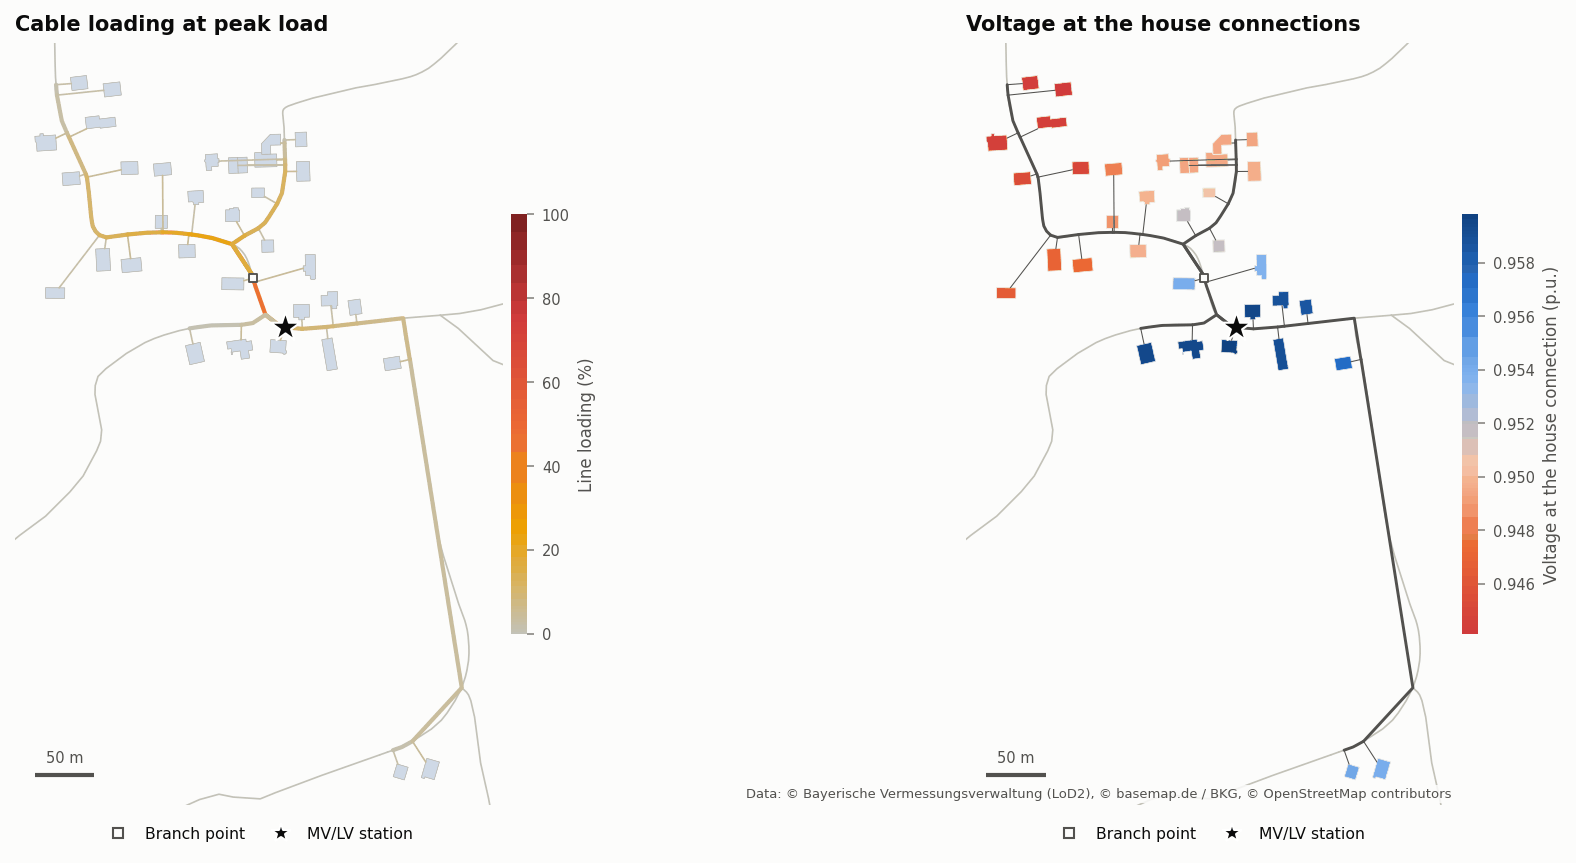

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.6))
lv_grid.plot_lv_grid(data.layers, kcid, bcid, color_by="loading", net=net, ax=axes[0], attribution="",
                     title="Cable loading at peak load")
lv_grid.plot_lv_grid(data.layers, kcid, bcid, color_by="voltage", net=net, ax=axes[1],
                     title="Voltage at the house connections");

- The first sections of each feeder carry the most current; the loading falls towards the ends.
- The voltage is lowest at the far ends of the long feeders, where the loading is low but the distance is large.

## 4 The grid as a tree

As a graph (networkx), the grid is a tree with the station at its root. Drawn with the cable distance as the
vertical axis (left) or as the radius (right), the long feeders stand out.

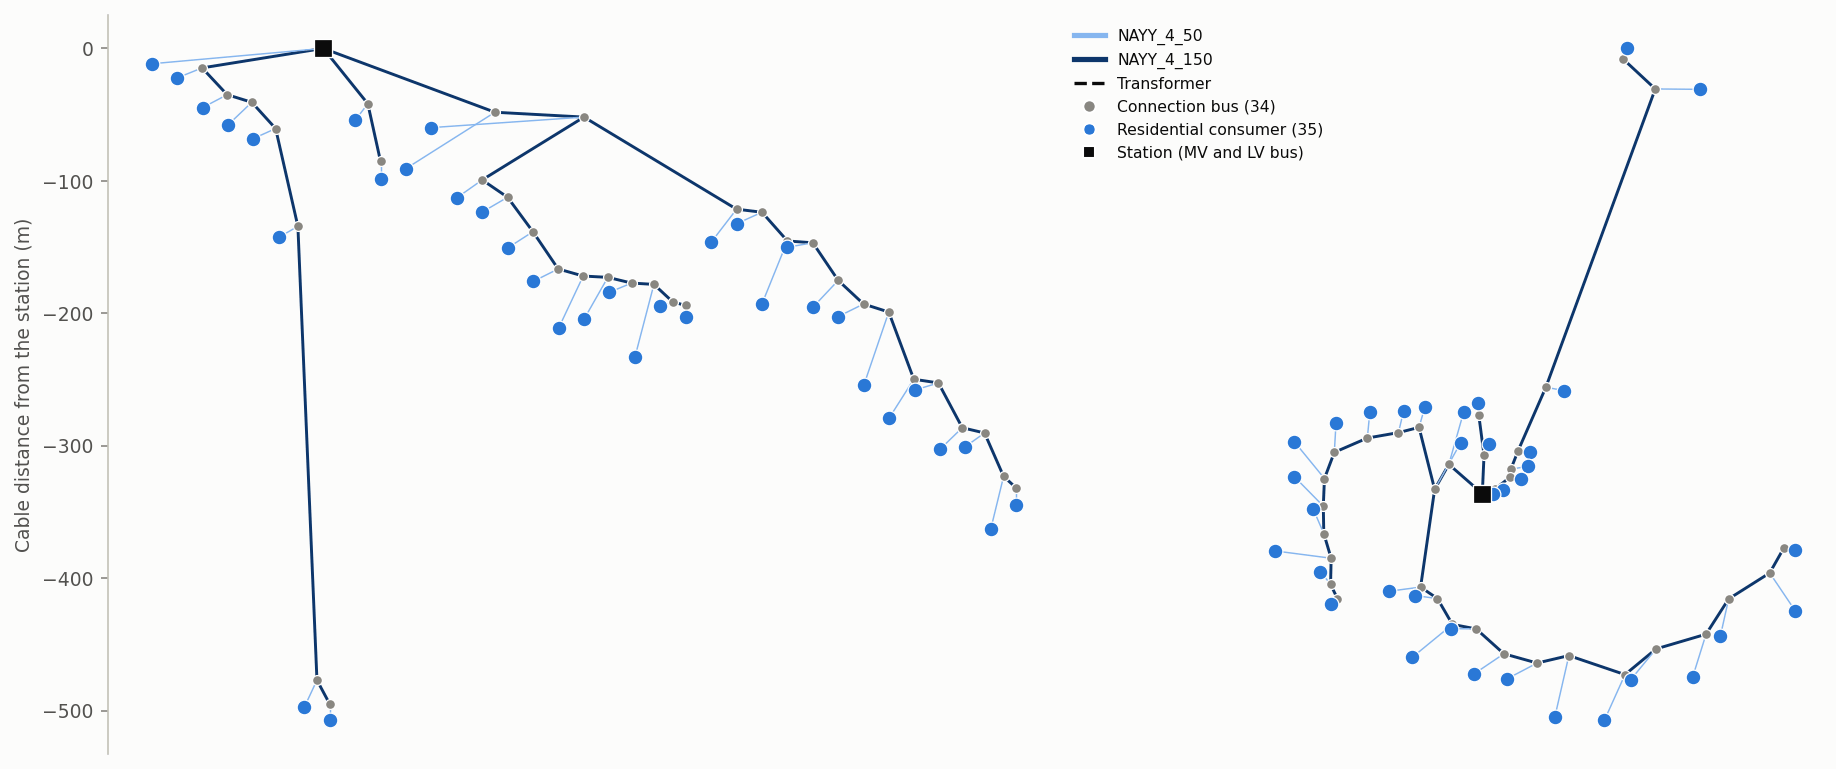

In [9]:
import pandapower.topology as top

from pylovo.plotting.generation import networks

graph = top.create_nxgraph(net)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.5, 1]})
networks.draw_tree_network(graph, net=net, y="distance", edge_color_by="cable", ax=axes[0])
networks.draw_radial_network(graph, net=net, radius="distance", edge_color_by="cable", ax=axes[1])
axes[1].get_legend().remove()                    # the same legend as on the left

## 5 Use the grid in other tools

The net can be saved like any pandapower net, for example for your own power-flow or time-series studies.

In [10]:
import tempfile
from pathlib import Path

import pandapower as pp

folder = Path(tempfile.mkdtemp())
pp.to_json(net, folder / "grid.json")
pp.to_excel(net, folder / "grid.xlsx")
{path.name: f"{path.stat().st_size / 1024:.0f} kB" for path in sorted(folder.iterdir())}

{'grid.json': '167 kB', 'grid.xlsx': '52 kB'}

For whole areas, `uv run pylovo-export` writes the grids of postcode areas as GeoPackage or CSV for QGIS, and the HTTP
API serves them to other programs ([exporting grids](https://pylovo.readthedocs.io/en/latest/user_guide/exporting_visualising.html)). The same grid
can also be solved with OpenDSS instead of pandapower ([electrical backends](https://pylovo.readthedocs.io/en/latest/concepts/electrical_backends.html)).